Q1.Equilibrium conversion checker

in a dilute liquid-phase reactor the reaction A+Bit gives C reaches equilibrium initial concentration are [A]=0.5 , [B]=0.5 and [C]=0 mol/L of c is formed, Kc=x/(0.5-x)^2 , which rerrange to the qudratic equation 

Kc.x^2 - (Kc+1).x + 0.25.Kc = 0

Write a python program that:

(a) reads Kc using input(), print the data type of the raw input and of the converted value , and shows a clear massage (no crash)if the text is not a number or if Kc<=0;

(b) finds a,b,c the discriminant and both roots

(c) selects the physically meaningful roots (0<=x<=0.5)

(d) print equilibrium [A],[B],[C] (3 decimal) and the conversion of the limiting reactant = x/[A].100(%);

(e) classifies the conversion using if / elif / else:>=70% "High",>=40% "Moderate",otherwise"Low".Test with Kc=6,Kc=0.5,Kc=abc and Kc=-2.

In [5]:
import math


def equilibrium_checker(raw_text=None):
    if raw_text is None:
        raw_text = input("Enter Kc: ")

    print("Raw input type:", type(raw_text).__name__)

    try:
        kc = float(raw_text)
    except (TypeError, ValueError):
        print("Invalid input: please enter a number for Kc.")
        return

    print("Converted value:", kc)
    print("Converted value type:", type(kc).__name__)

    if kc <= 0:
        print("Invalid Kc: the equilibrium constant must be greater than 0.")
        return

    # Kc*x^2 - (Kc+1)*x + 0.25*Kc = 0
    a = kc
    b = -(kc + 1)
    c = 0.25 * kc
    discriminant = b**2 - 4 * a * c

    print(f"a = {a}, b = {b}, c = {c}")
    print("Discriminant:", discriminant)

    if discriminant < 0:
        print("No real roots exist for this Kc.")
        return

    root1 = (-b + math.sqrt(discriminant)) / (2 * a)
    root2 = (-b - math.sqrt(discriminant)) / (2 * a)
    print(f"Both roots: {root1:.6f}, {root2:.6f}")

    physical_roots = [root for root in (root1, root2) if 0 <= root <= 0.5]
    if not physical_roots:
        print("No physically meaningful root in the range 0 <= x <= 0.5.")
        return

    x = physical_roots[0]
    concentration_a = 0.5 - x
    concentration_b = 0.5 - x
    concentration_c = x
    conversion = x / 0.5 * 100

    print(f"Physical root x: {x:.6f} mol/L")
    print(f"Equilibrium [A]: {concentration_a:.3f} mol/L")
    print(f"Equilibrium [B]: {concentration_b:.3f} mol/L")
    print(f"Equilibrium [C]: {concentration_c:.3f} mol/L")
    print(f"Limiting-reactant conversion: {conversion:.2f}%")

    if conversion >= 70:
        level = "High"
    elif conversion >= 40:
        level = "Moderate"
    else:
        level = "Low"

    print("Conversion classification:", level)


# Test cases; call equilibrium_checker() with no argument for interactive input.
for test_value in ("6", "0.5", "abc", "-2"):
    print(f"\n--- Test Kc = {test_value} ---")
    equilibrium_checker(test_value)



--- Test Kc = 6 ---
Raw input type: str
Converted value: 6.0
Converted value type: float
a = 6.0, b = -7.0, c = 1.5
Discriminant: 13.0
Both roots: 0.883796, 0.282871
Physical root x: 0.282871 mol/L
Equilibrium [A]: 0.217 mol/L
Equilibrium [B]: 0.217 mol/L
Equilibrium [C]: 0.283 mol/L
Limiting-reactant conversion: 56.57%
Conversion classification: Moderate

--- Test Kc = 0.5 ---
Raw input type: str
Converted value: 0.5
Converted value type: float
a = 0.5, b = -1.5, c = 0.125
Discriminant: 2.0
Both roots: 2.914214, 0.085786
Physical root x: 0.085786 mol/L
Equilibrium [A]: 0.414 mol/L
Equilibrium [B]: 0.414 mol/L
Equilibrium [C]: 0.086 mol/L
Limiting-reactant conversion: 17.16%
Conversion classification: Low

--- Test Kc = abc ---
Raw input type: str
Invalid input: please enter a number for Kc.

--- Test Kc = -2 ---
Raw input type: str
Converted value: -2.0
Converted value type: float
Invalid Kc: the equilibrium constant must be greater than 0.


Q2. batch reactor simulation and batch tracking

partA. A pollutant in wastewater is degraded in a batch photo reactor by a first-order reaction , dC/dt = -kC. Use the euler method :C_new=C_old-k.C_old.deltat. Take C = 1.0 mol/L,k=0.12min^-1 , deltat=0.5min.

(1)Using a for loop,simulate 5 min and print a table of time (min), Concentration (mol/L) and  conversion (%).

(2) Using math.exp(), calculate the exact value Ce^(-kt) at 5 min and print the absolute error of the euler result.

(3) using a while loop, repeat the simulation until conversion reaches 70% or time reaches 100min print the time needed and the final concentration 

partB. storage-tank lots such as TK0045-LOT19are stored as text. write a program that reads a lot code , loops through each character, and print the number of digits and the sum of the digits. show massage for an empty code and for a code with no digits. test with TK0045-LOT19, an empty code and ABCDEF 

In [1]:
import math

# Part A: Euler simulation for first-order degradation.
initial_concentration = 1.0
rate_constant = 0.12
time_step = 0.5
simulation_time = 5.0

concentration = initial_concentration
print("Part A(1): Euler simulation")
print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

for step in range(int(simulation_time / time_step) + 1):
    time = step * time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time:10.1f} {concentration:24.6f} {conversion:18.2f}")
    concentration = concentration - rate_constant * concentration * time_step

euler_concentration = concentration
exact_concentration = initial_concentration * math.exp(-rate_constant * simulation_time)
absolute_error = abs(euler_concentration - exact_concentration)

print("\nPart A(2): Exact result at 5 min")
print(f"Euler concentration: {euler_concentration:.6f} mol/L")
print(f"Exact concentration: {exact_concentration:.6f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# Restart from the initial concentration and step until the target is reached.
concentration = initial_concentration
time = 0.0
conversion = 0.0

while conversion < 70 and time < 100:
    concentration = concentration - rate_constant * concentration * time_step
    time += time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100

print("\nPart A(3): Time to reach 70% conversion")
if conversion >= 70:
    print(f"70% conversion reached at {time:.1f} min")
else:
    print("100 min reached before conversion reached 70%")
print(f"Final concentration: {concentration:.6f} mol/L")
print(f"Final conversion: {conversion:.2f}%")


# Part B: Count and sum decimal digits in a batch lot code.
def analyze_lot_code(lot_code=None):
    if lot_code is None:
        lot_code = input("Enter a lot code: ")

    if lot_code == "":
        print("Empty code: please enter a lot code.")
        return

    digit_count = 0
    digit_sum = 0
    for character in lot_code:
        if character.isdecimal():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("No digits found in the lot code.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


print("\nPart B: Lot-code tests")
for test_code in ("TK0045-LOT19", "", "ABCDEF"):
    print(f"\nLot code: {test_code!r}")
    analyze_lot_code(test_code)


Part A(1): Euler simulation
Time (min)    Concentration (mol/L)     Conversion (%)
       0.0                 1.000000               0.00
       0.5                 0.940000               6.00
       1.0                 0.883600              11.64
       1.5                 0.830584              16.94
       2.0                 0.780749              21.93
       2.5                 0.733904              26.61
       3.0                 0.689870              31.01
       3.5                 0.648478              35.15
       4.0                 0.609569              39.04
       4.5                 0.572995              42.70
       5.0                 0.538615              46.14

Part A(2): Exact result at 5 min
Euler concentration: 0.506298 mol/L
Exact concentration: 0.548812 mol/L
Absolute error: 0.042513 mol/L

Part A(3): Time to reach 70% conversion
70% conversion reached at 10.0 min
Final concentration: 0.290106 mol/L
Final conversion: 70.99%

Part B: Lot-code tests

Lot code: 'TK

Q3. Feed-blend screening and sampling scheduale

partA.a plant has n candidates feed components and wants to blend r of them (order does not matter). Write a recursive  function factorial(n) (remember the base case for 0!) and a function combinastion (n,r)=n!/(r!(n-r)!) that uses it. rejected invalid input (negative values, r>n). Print the number of possible blend for n=8, r=4, and  show the message for n=3,r=5.

partB. During a cooling experiment, temprature readings are taken at times = fibonacci number x 3 times. Write  an iterative function fib_iter(n) that returns a list of the first n fibonacci number, and a recursive function fib_rec(k) that returns the k-th fibonacci number (F=0,F1=1).For n=8, check that both functions agree and print a table:Readings No. | Fibonscci tag | Time(min).

In [2]:
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool):
        raise ValueError("n must be a non-negative integer.")
    if n < 0:
        raise ValueError("n must be non-negative.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if (not isinstance(n, int) or isinstance(n, bool)
            or not isinstance(r, int) or isinstance(r, bool)):
        return "Invalid input: n and r must be integers."
    if n < 0 or r < 0:
        return "Invalid input: n and r must be non-negative."
    if r > n:
        return "Invalid input: r cannot be greater than n."
    return factorial(n) // (factorial(r) * factorial(n - r))


print("Part A: Feed-blend combinations")
print("Number of blends for n=8, r=4:", combination(8, 4))
print("For n=3, r=5:", combination(3, 5))


def fib_iter(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 0:
        raise ValueError("n must be a non-negative integer.")

    sequence = []
    first, second = 0, 1
    for _ in range(n):
        sequence.append(first)
        first, second = second, first + second
    return sequence


def fib_rec(k):
    if not isinstance(k, int) or isinstance(k, bool) or k < 0:
        raise ValueError("k must be a non-negative integer.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


print("\nPart B: Fibonacci sampling schedule")
fibonacci_values = fib_iter(8)
recursive_values = [fib_rec(index) for index in range(8)]
print("Iterative and recursive results agree:", fibonacci_values == recursive_values)
print(f"{'Readings No.':>12} {'Fibonacci tag':>15} {'Time (min)':>12}")

for reading_number, fibonacci_tag in enumerate(fibonacci_values, start=1):
    time_minutes = fibonacci_tag * 3
    print(f"{reading_number:12d} {fibonacci_tag:15d} {time_minutes:12d}")


Part A: Feed-blend combinations
Number of blends for n=8, r=4: 70
For n=3, r=5: Invalid input: r cannot be greater than n.

Part B: Fibonacci sampling schedule
Iterative and recursive results agree: True
Readings No.   Fibonacci tag   Time (min)
           1               0            0
           2               1            3
           3               1            3
           4               2            6
           5               3            9
           6               5           15
           7               8           24
           8              13           39


Q4. Kinetics and gas data:pandas and matplotlib

photocatalytic degradation of a dye was studied at two UV intensities. The concentration (mol/L) was recorded:

Time_min    run1_mol_L(low UV)      run2_mol_L(high UV)
0               0.80                    0.80
10              0.54                    0.44
20              0.36                    0.24
30              0.24                    0.13
40              0.16                    0.07
50              0.11                    0.04

(a) creat a data frame from this table. Save it as kinetics.csv (without the index column) and as kinetics.json read the CSV back and print its shape and data types 

(b) print the mean and standerd deviation of run1 and run2, and state which run shows more variation.

(c) plot both runs on one graph(Time on x-axis) with title, axis labels with units, legend and grid.

(d) Air is compressed slowly in a piston-cylinder vessel constant temprature:

Volume_L         2      3       4       5       6
Pressure_bar    3.01    1.98    1.52    1.19    1.01

plot pressure vs. volume as a scatter plot. Calculate k as the mean of p x v and draw the reference curve P=k/v on the same graph. add title, labels with unit and legend 

Kinetics data read back from CSV:
Shape: (6, 3)
Data types:
Time_min        int64
run1_mol_L    float64
run2_mol_L    float64
dtype: object

Run statistics:
Run 1 mean: 0.3683 mol/L; standard deviation: 0.2617 mol/L
Run 2 mean: 0.2867 mol/L; standard deviation: 0.2904 mol/L
Run 2 shows more variation (larger standard deviation).


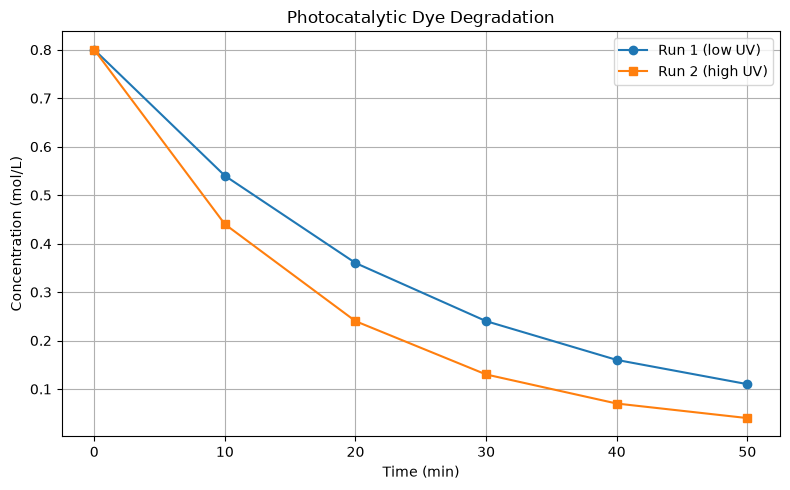


Mean P x V constant, k: 6.0100 bar·L


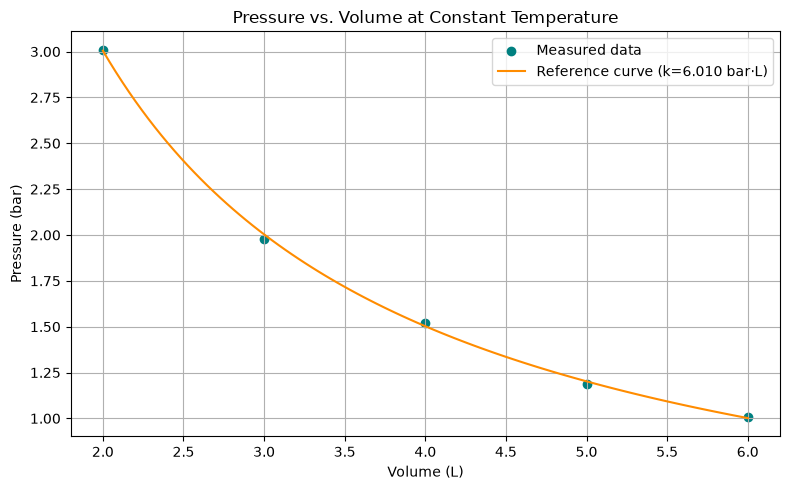

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Part A: Kinetics data, file output, and summary statistics.
kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "run1_mol_L": [0.80, 0.54, 0.36, 0.24, 0.16, 0.11],
    "run2_mol_L": [0.80, 0.44, 0.24, 0.13, 0.07, 0.04],
})

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("Kinetics data read back from CSV:")
print("Shape:", kinetics_from_csv.shape)
print("Data types:")
print(kinetics_from_csv.dtypes)

run1_mean = kinetics_from_csv["run1_mol_L"].mean()
run1_std = kinetics_from_csv["run1_mol_L"].std()
run2_mean = kinetics_from_csv["run2_mol_L"].mean()
run2_std = kinetics_from_csv["run2_mol_L"].std()

print("\nRun statistics:")
print(f"Run 1 mean: {run1_mean:.4f} mol/L; standard deviation: {run1_std:.4f} mol/L")
print(f"Run 2 mean: {run2_mean:.4f} mol/L; standard deviation: {run2_std:.4f} mol/L")
if run1_std > run2_std:
    print("Run 1 shows more variation (larger standard deviation).")
elif run2_std > run1_std:
    print("Run 2 shows more variation (larger standard deviation).")
else:
    print("Both runs show the same variation (equal standard deviations).")

plt.figure(figsize=(8, 5))
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["run1_mol_L"], marker="o", label="Run 1 (low UV)")
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["run2_mol_L"], marker="s", label="Run 2 (high UV)")
plt.title("Photocatalytic Dye Degradation")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Part D: Pressure-volume data and the idealized reference curve.
volume_l = np.array([2, 3, 4, 5, 6], dtype=float)
pressure_bar = np.array([3.01, 1.98, 1.52, 1.19, 1.01], dtype=float)
k_value = np.mean(pressure_bar * volume_l)
reference_volumes = np.linspace(volume_l.min(), volume_l.max(), 100)
reference_pressures = k_value / reference_volumes

print(f"\nMean P x V constant, k: {k_value:.4f} bar·L")

plt.figure(figsize=(8, 5))
plt.scatter(volume_l, pressure_bar, label="Measured data", color="teal")
plt.plot(reference_volumes, reference_pressures, label=f"Reference curve (k={k_value:.3f} bar·L)", color="darkorange")
plt.title("Pressure vs. Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
